# Figure 2 — Cortical representations of spontaneous behaviors

In [2]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi 

In [4]:
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

data_root =  str(PREPARES / "epochs-rest-to-running") + "/"
mouse='cm125'

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_30164/3017678801.py:7: RuntimeWarning: invalid value encountered in cast
  props = regionprops(IDX_sorted.astype(int))


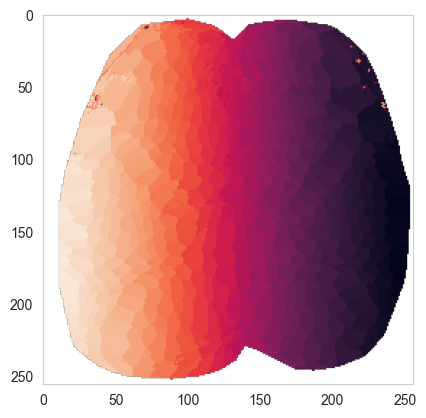

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)

In [6]:
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
# all_ind = sensory_ind.copy()
# extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)
# extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
# all_ind.update(extra_ind)



In [7]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


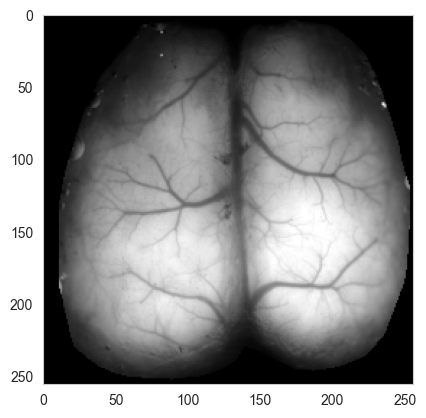

In [8]:
masked_brain = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain,0)
plt.imshow(masked_brain,cmap='gray',vmin=500,vmax=4500)

In [9]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

In [10]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model


**load data**

In [11]:
choice_body_part_dict = {0:'RHP',1:'RFP',2:'RW',3:'RV',
                         4:'RM_M2',5:'RFP_M2',6:'LatM'}
choice_dict = {0:316,1:400,2:sensory_ind['RW'],3:406,4:[],5:[],6:418}

In [12]:
behavior_colors = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488',
                  '#F39B7F', '#8491B4', '#91D1C2FF','#7E6148','#B09C85', '#DC0000'
                   ]

In [13]:
col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
col_list_palette = sns.xkcd_palette(col_list)

### load rest-running epochs

In [14]:
load_list = ['norm_M_jrgeco', 'norm_M_rotf', 'norm_M_face_pc', 'norm_M_body_pc', 'norm_M_pupil_pc_norm', 
 'norm_M_whisk_vel_norm', 'norm_M_nose_vel_norm', 'norm_M_LFP_vel_norm', 'norm_M_RFP_vel_norm',
 'M_day_label', 'M_is_groom', 'M_ind', 'norm_M_mirrorRFP_vel_norm', 'norm_M_mirrorLFP_vel_norm', 
 'norm_M_mirrorRHP_vel_norm', 'norm_M_mirrorLHP_vel_norm']

f = scipy.io.loadmat(data_root+'final_'+mouse+'_norm.mat')

for item in load_list:
    exec("{}=np.squeeze(f['{}'])".format(item,item))
T_PRE=190;
T_POST=300;
T=T_PRE+T_POST


In [15]:
load_filename = data_root+'final_'+mouse+'_MM_full.h5'
# Load and baseline-subtract in blocks of 16 rows. The original built a second
# full-size array here (np.array(...), then MM_jrgeco - np.mean(...)), so it needed two
# copies of the stack live at once: 2 x 31.7 GB = 63.5 GB for cm125, which OOM-kills a
# 48 GB machine (exit 137). This holds one 31.7 GB array plus one ~2 GB block, and
# reads stay sequential; measured on an M4 Pro it finishes in 49 s with 6.4 GB max
# resident.
# Bit-identical to the original: np.array_equal(..., equal_nan=True) is True, because
# blocking along axis 0 leaves the axis-2 reduction untouched. See
# a memory-safe chunked loader.
with h5py.File(load_filename, 'r') as hf:
    dset = hf['MM_jrgeco']
    MM_jrgeco = np.empty(dset.shape, dtype=dset.dtype)
    for i_x0 in range(0, dset.shape[0], 16):
        blk = dset[i_x0:i_x0 + 16]
        MM_jrgeco[i_x0:i_x0 + 16] = blk - np.mean(blk[:,:,T_PRE-100:T_PRE,:],2)[:,:,np.newaxis,:]
    del blk, dset

In [16]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')

list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]

jrgeco2plot_M2 = {};node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
    small_roi_tcs = np.nanmean(np.nanmean(
        MM_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot_M2[bdp] = small_roi_tcs
    
H_jrgeco_new_bsl=getH_4D(MM_jrgeco,IDX_sorted)

In [17]:
behaviros_body_w_order = ['norm_M_mirrorRHP_vel_norm',
                     'norm_M_LFP_vel_norm',
                     'norm_M_RFP_vel_norm',
                     'norm_M_rotf']
behaviros_face_w_order = ['norm_M_whisk_vel_norm','norm_M_pupil_pc_norm','norm_M_face_pc']
palette_body=['#0c4666','#adcee9','#f4c784','#e97877']
# palette_face=['#7B4EA1','#2A7377','#D15134','#BAB2AC','#2C5B78','#FFAE4E',]
palette_face=['#7B4EA1','palevioletred','#D15134','#BAB2AC','#2C5B78','#FFAE4E',]
# palette_face = [ '#DC63AA' ,'#232F17', '#D15134']
all_bev_short_dict={'norm_M_whisk_vel_norm':'whisk',
                    'norm_M_nose_vel_norm':'nose',
                    'norm_M_mirrorLHP_vel_norm':'mLHP','norm_M_mirrorRHP_vel_norm':'mRHP',
                     'norm_M_mirrorLFP_vel_norm':'mLFP','norm_M_mirrorRFP_vel_norm':'mRFP','norm_M_LFP_vel_norm':'LFP',
                      'norm_M_RFP_vel_norm':'RFP','norm_M_rotf':'rotary','norm_M_body_pc':'body PC','norm_M_face_pc':'face PC',
                    'norm_M_pupil_pc_norm':'pupil PC'}

In [18]:
palatte_dict['RM_M2']='#bf8fc9'
palatte_dict['RFP_M2']='#6dae96'
palatte_dict['RFP_M1']='#4b0082'
# palatte_dict['RV']='lightseagreen'
palatte_dict['LatM']=palatte_dict['ALM']

In [19]:
jrgeco2plot ={}
norm_jrgeco_zscored_std = {}
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    if len(bdp.split('_'))==1:
        jrgeco2plot[bdp]=H_jrgeco_new_bsl[ind,:,:]
        norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values
    else:
        if bdp.split('_')[1] == 'M2':
            jrgeco2plot[bdp] = jrgeco2plot_M2[bdp.split('_')[0]]
            norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values
        else:
            jrgeco2plot[bdp] = H_jrgeco_new_bsl[ind,:,:] # RFP M1
            norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values


/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_30164/1913865009.py:8: FutureWarning: The 'axis' keyword in DataFrame.rolling is deprecated and will be removed in a future version. Call the method without the axis keyword instead.
  norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_30164/1913865009.py:8: FutureWarning: The 'axis' keyword in DataFrame.rolling is deprecated and will be removed in a future version. Call the method without the axis keyword instead.
  norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_30164/1913865009.py:8: FutureWarning: The 'axis' keyword in DataFrame.rolling is deprecated and will be removed in a future version. Call the method without the axis keyword instead.
  norm_jrgeco_zscored_std[bdp] = pd.Data

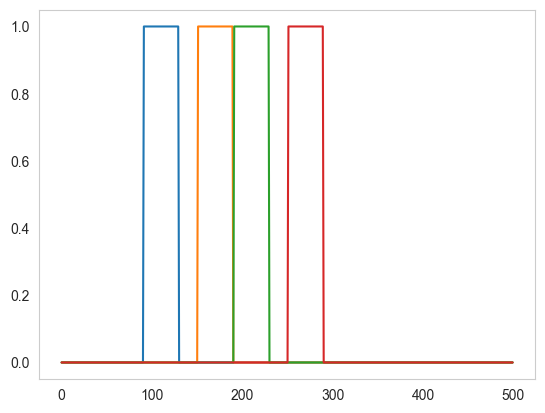

In [20]:
T = norm_M_body_pc.shape[0]
t_ax = np.divide(range(-T_PRE,T-T_PRE),20)

win1 = np.logical_and(t_ax>-5,t_ax<-3)
win2 = np.logical_and(t_ax>-2,t_ax<-0)
win3 = np.logical_and(t_ax>0,t_ax<2)
win4 = np.logical_and(t_ax>3,t_ax<5)


plt.plot(win1)
plt.plot(win2)
plt.plot(win3)
plt.plot(win4)
# plt.xlim([290,300])|

## Fig 2g — averaged time courses

Behaviour signals, neural amplitude for 7 ROIs, and the rolling-window standard
deviation (temporal variance). Mean ± s.e.m., n=130 bouts. The four analysis windows
(rest 1, rest 2, run 1, run 2) marked in the bottom row are the ones panels d/e average
over.


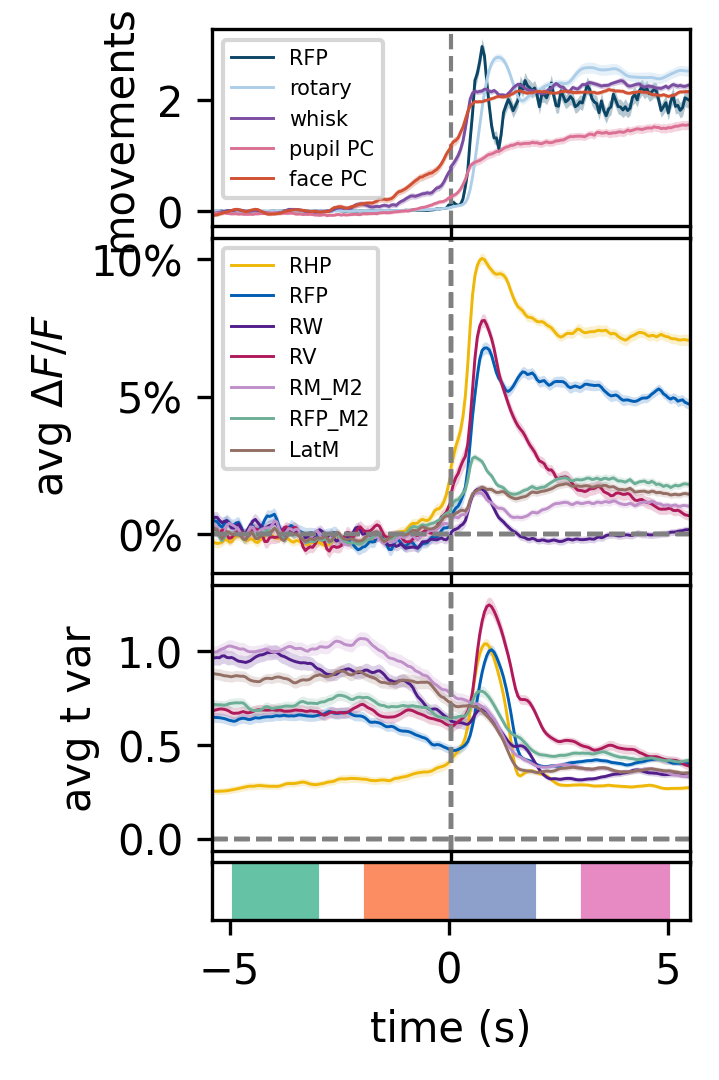

In [21]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;x_width=5

# behavior (body and facial movements)
x_start = x_offset 
x_stop = x_start+7
y_start = y_offset 
y_stop = y_start+3
for i_ax in range(0,3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop
    y_stop = y_start+5
    if i_ax == 1:
        y_stop = y_start+4
    exec("ax{}.set_xticklabels([])".format(i_ax)) 
    
ax3 = fig.add_subplot(gs[y_start:y_start+1,x_start:x_stop])
ax3.set_yticks([])

########################################
########################################
lwidth = 0.7


t_frame_trimmed = np.linspace(-100,100,200).astype('int')
t_ax_trimmed = np.divide(t_frame_trimmed,20)

# ampltitude
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]   
    data2plot = jrgeco2plot[bdp][T_PRE-100:T_PRE+100,:]
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax1.plot(t_ax_trimmed,avg,color=palatte_dict[bdp],linewidth = lwidth,label=bdp)
    ax1.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp],alpha=0.2,lw=0)
    ax1.axvline(0,linewidth=1,linestyle='dashed',color='gray')
    ax1.axhline(0,linewidth=1,linestyle='dashed',color='gray')
    ax1.set_yticks([0,0.05,0.1])
    vals = ax1.get_yticks()
    ax1.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
    ax1.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    # ax2.set_yticklabels([])

    
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    data2plot = norm_jrgeco_zscored_std[bdp][T_PRE-100:T_PRE+100,:]
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax2.plot(t_ax_trimmed,avg,color=palatte_dict[bdp],linewidth = lwidth,label=bdp)
    ax2.fill_between(t_ax_trimmed, avg - sem,avg + sem,lw=0,color=palatte_dict[bdp],alpha=0.2)
    ax2.axvline(0,linewidth=1,linestyle='dashed',color='gray')
    # ax1.set_yticks([-0.2,0,0.02])
    ax2.axhline(0,linewidth=1,linestyle='dashed',color='gray')
    ax2.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    # ax1.set_xticklabels([])


    
# NOW plot behavior
# body movements

behaviros_body_w_order = ['norm_M_RFP_vel_norm',
                     'norm_M_rotf']
behaviros_face_w_order = ['norm_M_whisk_vel_norm','norm_M_pupil_pc_norm','norm_M_face_pc']


for i_behavior,behavior in enumerate(behaviros_body_w_order):
    exec("beh2plot = {}[T_PRE-100:T_PRE+100,:]".format(behavior))
    avg = np.mean(beh2plot,axis=1)#+i_behavior*2.5
    sem = stats.sem(beh2plot,axis=1)
    ax0.plot(t_ax_trimmed,avg,color=palette_body[i_behavior],linewidth = lwidth, label=all_bev_short_dict[behavior])
    ax0.fill_between(t_ax_trimmed, avg - sem,avg + sem,lw=0,color=palette_body[i_behavior],alpha=0.3)
    ax0.set_xlim(np.divide([-100,100],20))
    # ax2.text(t_ax[0]+0.3,i_behavior*2.5+0.35,all_bev_short_dict[behavior],color=behavior_colors[i_behavior],fontsize=10)


ax0.axvline(0,linewidth=1,linestyle='dashed',color='gray')
  



for i_behavior,behavior in enumerate(behaviros_face_w_order):
    exec("beh2plot = {}[T_PRE-100:T_PRE+100,:]".format(behavior))
    avg = np.mean(beh2plot,axis=1)#+i_behavior*2.5
    sem = stats.sem(beh2plot,axis=1)
    ax0.plot(t_ax_trimmed,avg,color=palette_face[i_behavior],linewidth = lwidth,label=all_bev_short_dict[behavior])
    ax0.fill_between(t_ax_trimmed, avg - sem,avg + sem,lw=0,color=palette_face[i_behavior],alpha=0.3)
    ax0.set_xlim(np.divide([-100,100],20))
    # ax2.text(t_ax[0]+0.3,i_behavior*2.5+0.35,all_bev_short_dict[behavior],color=behavior_colors[i_behavior],fontsize=10)


for i_win,win in enumerate(['win1','win2','win3','win4']):
    exec("win_here = {}[T_PRE-100:T_PRE+100]".format(win))
    ax3.vlines(t_ax_trimmed[np.where(win_here==True)], 0, 0.5,linewidth=1,color=sns.color_palette("Set2")[i_win])
    ax3.vlines(0, 8, 9,linewidth=10,color=sns.color_palette("Set2")[i_win],label=win_here)#for the legend
ax3.set_ylim([0,0.5])
    
    
####
ax0.legend(fontsize=5)
ax1.legend(fontsize=5)
# ax2.legend(fontsize=5)
ax1.set_ylabel('avg $\Delta F/F$')
ax2.set_ylabel('avg t var')
ax0.set_ylabel('movements');  
ax3.set_xlabel('time (s)')
###
plt.savefig('fig2-left-panel-TCs.svg',format='svg',dpi=300)

# brain

In [22]:
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T

In [23]:
norm_M_jrgeco_zscore = norm_M_jrgeco.copy()
norm_M_jrgeco_zscore = stats.zscore(norm_M_jrgeco_zscore,axis=1)
ss = norm_M_jrgeco.shape
norm_M_jrgeco_zscore_std = np.empty((ss[0],ss[1],0))
for i_bout in range(ss[2]):
    temp = pd.DataFrame(norm_M_jrgeco_zscore[:,:,i_bout]).T.rolling(20).std().T.values
    norm_M_jrgeco_zscore_std=np.append(norm_M_jrgeco_zscore_std,temp[:,:,np.newaxis],axis=2)

    

In [24]:
map_norm_M_jrgeco_by_win = {}
map_norm_M_jrgeco_zscore_std_by_win = {}
for i_win,win in enumerate(['win1','win2','win3','win4']):
    
    exec("avg_temp = np.mean(np.mean(norm_M_jrgeco[:,{},:],axis=1),axis=-1)".format(win))
    map_norm_M_jrgeco_by_win[win] = np.multiply(show_map(avg_temp,
                                      [0,2],cmap='coolwarm',if_return_map=True,IDX_sorted=IDX_sorted),
                                             mask_midline)   


    exec("avg_temp = np.mean(np.mean(norm_M_jrgeco_zscore_std[:,{},:],axis=1),axis=-1)".format(win))
    map_norm_M_jrgeco_zscore_std_by_win[win] = np.multiply(show_map(avg_temp,
                                      [0,2],cmap='coolwarm',if_return_map=True,IDX_sorted=IDX_sorted),
                                            mask_midline)   



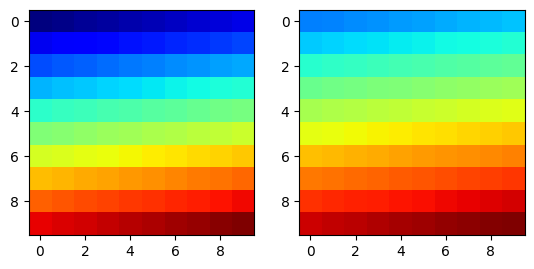

In [26]:
import matplotlib.colors as colors
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

arr = np.linspace(0, 50, 100).reshape((10, 10))
fig, ax = plt.subplots(ncols=2)

cmap = plt.get_cmap('jet')
new_cmap = truncate_colormap(cmap, 0.25, 1)
ax[0].imshow(arr, interpolation='nearest', cmap=cmap)
ax[1].imshow(arr, interpolation='nearest', cmap=new_cmap)
plt.show()

cmap = plt.get_cmap('jet')
new_cmap = truncate_colormap(cmap, 0.25, 1)

## Fig 2d, 2e — average activation and temporal-variance maps

Maps of mean ΔF/F (d) and of the moving-window standard deviation (e) for the four time
windows defined above. n=130 bouts.


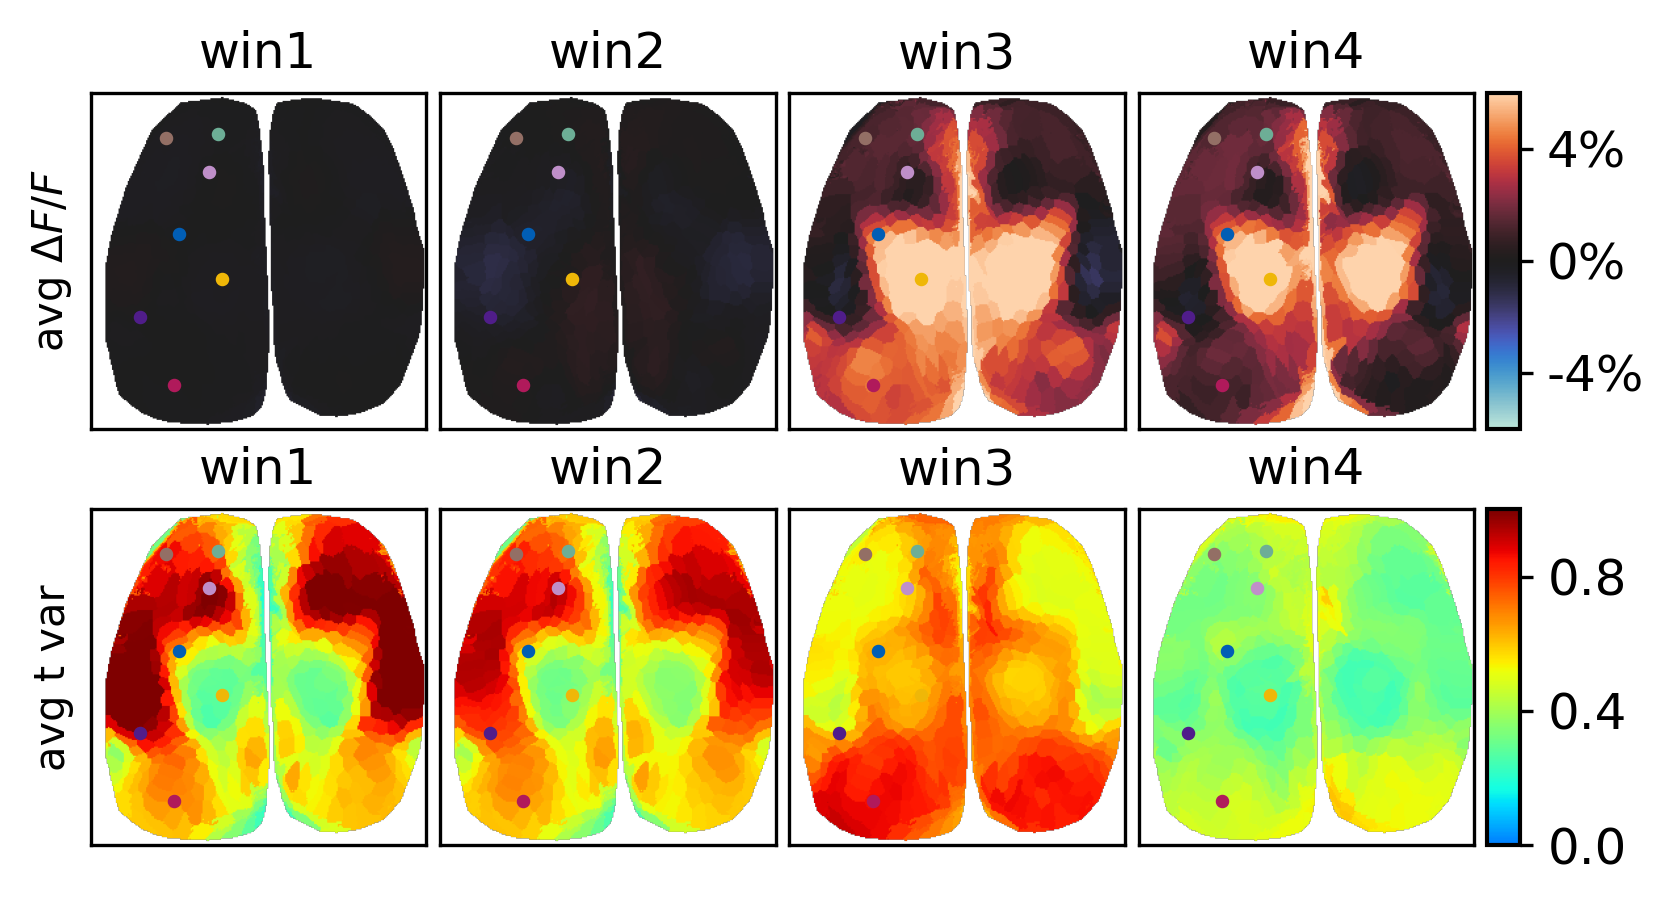

In [27]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;x_width=5


# temporal std average brain map (rest and run)
x_start = x_offset 
x_stop = x_offset+x_width
for i_ax in range(0,4):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start + x_width
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))    

ax990 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_start+2])

x_start = x_offset 
x_stop = x_offset+x_width
for i_ax in range(4,8):
    exec("ax{} = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start + x_width
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))    

ax991 = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_start+2])
########################################
########################################



# t_frame_trimmed = np.linspace(-100,100,200).astype('int')
# t_ax_trimmed = np.divide(t_frame_trimmed,20)


# map_norm_M_jrgeco_by_win 
# map_norm_M_jrgeco_zscore_std_by_win 
for i_win,win in enumerate(['win1','win2','win3','win4']):
    exec("sbp1 = ax{}.imshow(map_norm_M_jrgeco_by_win[win],vmin=-0.06,vmax=0.06,aspect='equal',cmap='icefire')".format(i_win))
    exec("ax{}.set_title(win)".format(i_win))
    for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
        ind = choice_dict[i_bdp]
        bdp = choice_body_part_dict[bdp_ind]
        if len(bdp.split('_'))==1:
            exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_win))
        else:
            if bdp.split('_')[1] == 'M2':
                exec("ax{}.scatter(node_coords_M2[bdp.split('_')[0]][0], node_coords_M2[bdp.split('_')[0]][1], s=5, c=palatte_dict[bdp], zorder=2)".format(i_win))
            else:
                exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_win))

# #####brain maps

for i_win,win in enumerate(['win1','win2','win3','win4']):
    exec("sbp2 = ax{}.imshow(map_norm_M_jrgeco_zscore_std_by_win[win],vmin=-0.0,vmax=1,aspect='equal',cmap=new_cmap)".format(i_win+4))
    exec("ax{}.set_title(win)".format(i_win+4))
    for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
        ind = choice_dict[i_bdp]
        bdp = choice_body_part_dict[bdp_ind]
        if len(bdp.split('_'))==1:
            exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_win+4))
        else:
            if bdp.split('_')[1] == 'M2':
                exec("ax{}.scatter(node_coords_M2[bdp.split('_')[0]][0], node_coords_M2[bdp.split('_')[0]][1], s=5, c=palatte_dict[bdp], zorder=2)".format(i_win+4))
            else:
                exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_win+4))
    
    # for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
    #     ind = choice_dict[i_bdp]
    #     bdp = choice_body_part_dict[bdp_ind]
    #     exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=3,color=palatte_dict[bdp])".format(i_win+4))
    

for i_count,i_ax in enumerate([3,7]):
    if i_ax==3:
        exec("cb = fig.colorbar(sbp1, cax=ax99{},fraction=0.5,orientation='vertical',format=FuncFormatter(fmt));".format(i_count))
    else:
        exec("cb = fig.colorbar(sbp2, cax=ax99{},fraction=0.5,orientation='vertical');".format(i_count))
    cb.ax.tick_params(labelsize=12,length=3,color='black')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('black')
    cb.outline.set_linewidth(1)
    tick_locator = ticker.MaxNLocator(nbins=3)
    cb.locator = tick_locator
    cb.update_ticks()
    if i_ax==3:
        exec("ax99{}.set_aspect(85);ax99{}.set_anchor('W')".format(i_count,i_count))
    if i_ax==7:
        exec("ax99{}.set_aspect(10);ax99{}.set_anchor('W')".format(i_count,i_count))
        
        
# ####
ax0.set_ylabel('avg $\Delta F/F$')
ax4.set_ylabel('avg t var')
# ax2.legend(fontsize=5)
# ###
plt.savefig('fig2-brain-maps-movie.svg',format='svg',dpi=300)

# STATS

In [28]:
stats_root = str(FIGURES / "figure3") + "/"

In [29]:
diff_pot_all = pd.DataFrame()
paired_t_pot_all = pd.DataFrame()
for mouse_here in ['cm125','cm126','cm128']:
    stats_dict = load_pickle(stats_root+'stats_'+mouse_here)
    diff_pot_all = pd.concat([diff_pot_all, stats_dict['diff_pot']])
    paired_t_pot_all = pd.concat([paired_t_pot_all, stats_dict['paired_t_pot']])

    
    

In [30]:
diff_pot = diff_pot_all.replace('LM_M2','RM_M2').replace('LFP_M2','RFP_M2')
diff_pot = diff_pot.loc[diff_pot['region'].isin(['RM_M2','RFP_M2','LatM'])]
paired_t_pot = paired_t_pot_all.replace('LM_M2','RM_M2').replace('LFP_M2','RFP_M2')

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_30164/2775769006.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  paired_t_pot = paired_t_pot_all.replace('LM_M2','RM_M2').replace('LFP_M2','RFP_M2')


In [31]:
all_body_part = [choice_body_part_dict[item] for item in choice_body_part_dict]

In [32]:
def new_adjust_box_widths(axes, fac=0.9):
    """
    Adjust the widths of a seaborn-generated boxplot or boxenplot.
    
    Notes
    -----
    - thanks https://github.com/mwaskom/seaborn/issues/1076
    """
    from matplotlib.patches import PathPatch
    from matplotlib.collections import PatchCollection
    
    if isinstance(axes, list) is False:
        axes = [axes]

        
    x_offsets = [-0.8, 0.8]  # Adjust these values to control the separation between hue categories


    display_coordinates_1=[]
    display_coordinates_2=[]
        
        
    # iterating through Axes instances
    for ax in axes:

        # iterating through axes artists:
        for c in ax.get_children():
            # searching for PathPatches
            if isinstance(c, PathPatch) or isinstance(c, PatchCollection):
                if isinstance(c, PathPatch):
                    p = c.get_path()
                    x0_here = c.get_extents().x0
                else:
                    p = c.get_paths()[-1]
                    print('hii')
                    

        
                # getting current width of box:
#                 p = c.get_path()
                verts = p.vertices
                verts_sub = verts[:-1]
                xmin = np.min(verts_sub[:, 0])
                xmax = np.max(verts_sub[:, 0])
                xmid = 0.5 * (xmin + xmax)
                xhalf = 0.5 * (xmax - xmin)

                # setting new width of box
                xmin_new = xmid - fac * xhalf
                xmax_new = xmid + fac * xhalf
                verts_sub[verts_sub[:, 0] == xmin, 0] = xmin_new
                verts_sub[verts_sub[:, 0] == xmax, 0] = xmax_new

                # setting new width of median line
                for l in ax.lines:
                    try:
                        if np.all(l.get_xdata() == [xmin, xmax]):
                            l.set_xdata([xmin_new, xmax_new])
                    except:
                        # /tmp/ipykernel_138835/916607433.py:32: DeprecationWarning: elementwise comparison failed;
                            # this will raise an error in the future.
                                # if np.all(l.get_xdata() == [xmin, xmax]):
                        pass
    pass

## Fig 2i — change in temporal variance, three frontal regions × three mice

Window "run 2" minus "rest 1".


--- Figure 3 Individual Mouse Statistics Saved ---
   Mouse  Region  N_Bouts     t_stat       p_value   Cohen_d Significance
0  cm125   RM_M2      130 -24.559039  1.793309e-50 -2.153970         ****
1  cm125  RFP_M2      130 -11.658296  6.763978e-22 -1.022500         ****
2  cm125    LatM      130 -19.832655  5.391083e-41 -1.739439         ****
3  cm126   RM_M2       41  -9.584274  6.476542e-12 -1.496812         ****
4  cm126  RFP_M2       41  -4.741126  2.691295e-05 -0.740440         ****
5  cm126    LatM       41  -8.997931  3.703152e-11 -1.405241         ****
6  cm128   RM_M2       28  -6.459945  6.356400e-07 -1.220815         ****
7  cm128  RFP_M2       28  -3.130920  4.158261e-03 -0.591688           **
8  cm128    LatM       28  -8.141876  9.575175e-09 -1.538670         ****


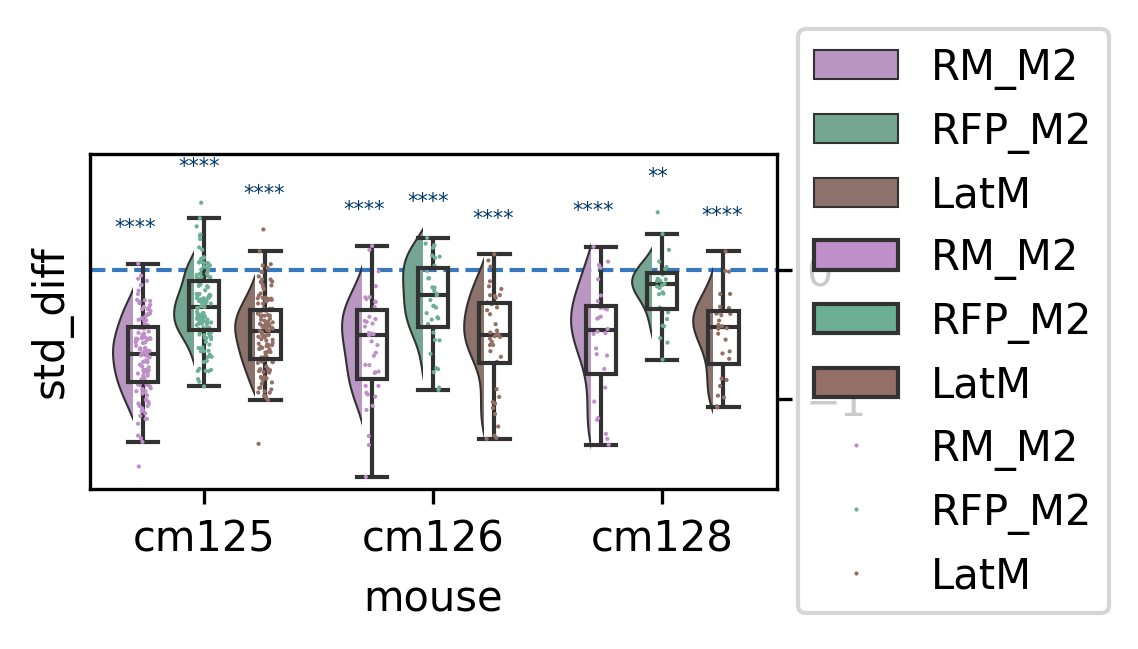

In [33]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from scipy.stats import ttest_1samp  # Added for live statistics
import numpy as np
import pandas as pd

fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20; x_offset=20; x_width=5

# temporal std average brain map (rest and run)
x_start = x_offset 
x_stop = x_offset+10
ax0 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])


my_pal = {key:palatte_dict[key] for i,key in enumerate(all_body_part)}


ax_violin = sns.violinplot(x="mouse", y="std_diff", hue="region", palette=my_pal,
       data=diff_pot,density_norm="width", linewidth=0.5,inner=None,ax=ax0)

# Half-violin masking
for violin in ax_violin.collections:
    bbox = violin.get_paths()[0].get_extents()
    x0, y0, width, height = bbox.bounds
    violin.set_clip_path(plt.Rectangle((x0-0.05, y0), width / 2, height, transform=ax_violin.transData))
        
sns.boxplot(x="mouse", y="std_diff", hue="region", palette=my_pal,
       data=diff_pot,dodge=True,
            saturation=1, showfliers=False,boxprops={'zorder': 5, 'facecolor': 'none'},
            linewidth=1, ax=ax0)

try:
    new_adjust_box_widths(ax0, fac=0.5)
except NameError:
    pass

sns.stripplot(x="mouse", y="std_diff", hue="region",palette=my_pal,
       data=diff_pot,dodge=True,
    color='dodgerblue',size=1, ax=ax0)
    
ax0.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax0.axhline(0,color='#3778bf',linewidth=1,linestyle='dashed',zorder=0)

fsz = 5

# ---> NEW: Initialize an empty list to store your stats
stats_output = [] 

# Live Statistical Annotation & Data Saving
for i, mouse in enumerate(['cm125','cm126','cm128']):
    for j, region in enumerate(['RM_M2','RFP_M2','LatM']):
        # Isolate data for this specific region/mouse
        data_slice = diff_pot.loc[(diff_pot['mouse']==mouse) & (diff_pot['region']==region), 'std_diff'].dropna()
        
        # Calculate Y-position for the star above the local maximum
        y = data_slice.max() + 0.002
        
        # Calculate paired t-test against 0 and Cohen's d
        if len(data_slice) > 1:
            stat, p_val = ttest_1samp(data_slice, popmean=0)
            cohen_d = data_slice.mean() / data_slice.std()
        else:
            stat, p_val, cohen_d = np.nan, 1.0, np.nan # Failsafe if data is missing
        
        # Apply stars based on the fresh p-value
        if p_val < 0.0001: star = "****"
        elif p_val < 0.001: star = "***"
        elif p_val < 0.01: star = "**"
        elif p_val < 0.05: star = "*"
        else: star = "n.s."
            
        # Draw the star on the plot
        plt.text(i+0.28*j-0.3, y+0.2, star, ha='center', va='bottom', color='#01386a',fontsize=fsz)
        
        # ---> NEW: Append the calculated stats to our tracker
        stats_output.append({
            'Mouse': mouse,
            'Region': region,
            'N_Bouts': len(data_slice),
            't_stat': stat,
            'p_value': p_val,
            'Cohen_d': cohen_d,
            'Significance': star
        })

ax0.set_ylim([-1.7,0.9])
ax0.yaxis.tick_right()
plt.savefig('fig2-STATS-per-mouse-rollingstd.svg',format='svg',dpi=300)

# ---> NEW: Convert the tracked stats to a DataFrame, save to CSV, and print to console
stats_df = pd.DataFrame(stats_output)
# stats_df.to_csv('fig3_individual_mouse_stats.csv', index=False)

print("\n--- Figure 3 Individual Mouse Statistics Saved ---")
print(stats_df)

In [ ]:
with open(stats_root + 'stats_pooled_seedbox_current.pkl', 'rb') as f:
    pooled = pickle.load(f)

PAWS    = ['RFP', 'RHP']            # forepaw + hindpaw S1
FRONTAL = ['RM_M2', 'RFP_M2', 'LatM']   # front_1, front_2, lateral_1


def grouped_cohens_d(df, regions, col):
    d = df[df['region'].isin(regions)][col].dropna()
    return d.mean() / d.std()


for col, label in [('mean_diff', 'amplitude'), ('std_diff', 'rolling s.d.')]:
    print(f'{label:13s} paws (HP+FP) {grouped_cohens_d(pooled, PAWS, col):+.3f}'
          f'   frontal {grouped_cohens_d(pooled, FRONTAL, col):+.3f}')


amplitude     paws (HP+FP) +2.384   frontal +0.956
rolling s.d.  paws (HP+FP) -0.400   frontal -1.317
